# PREDIKSI JENIS POHON DI SUATU AREA BERDASARKAN KONDISI GEOGRAFIS DAN LINGKUNGAN

In [164]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [165]:
df = pd.read_csv('covtype.csv')

# dengan terpaksa saya memangkas jumlah row dari dataset ini dari 460k++ menjadi 100k, karna 460k++ terlalu berat untuk algoritma KNN
df = df.sample(n=100000, random_state=4)

In [166]:
# 5 data teratas
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
238870,3117,357,14,360,-57,1381,198,214,154,1209,...,0,0,0,0,0,0,0,0,0,1
104324,3073,71,19,150,-3,3852,238,199,85,3817,...,0,0,0,0,0,0,0,0,0,1
114383,2717,355,3,342,50,994,215,234,157,1891,...,0,0,0,0,0,0,0,0,0,1
509947,3243,103,18,513,82,1140,247,214,89,1869,...,0,0,0,0,0,0,0,0,0,1
151206,3091,238,18,684,114,6217,185,252,201,1492,...,0,0,0,0,0,0,0,0,0,2


In [167]:
# 5 data terbawah
df.tail()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
519497,3154,28,18,720,94,1679,209,197,118,2155,...,0,1,0,0,0,0,0,0,0,1
203802,3193,165,11,95,13,5298,230,244,144,1168,...,0,0,0,0,0,0,0,0,0,1
89809,2753,342,8,395,55,2037,205,229,163,2128,...,0,0,0,0,0,0,0,0,0,2
328710,2948,72,9,242,56,1770,231,223,125,1907,...,0,0,0,0,0,0,0,0,0,2
225231,2520,47,24,120,53,603,220,180,81,782,...,0,1,0,0,0,0,0,0,0,2


In [168]:
# kolom yang ada di dataset
df.columns

Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1',
       'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4',
       'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5',
       'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10',
       'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14',
       'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18',
       'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22',
       'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26',
       'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30',
       'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34',
       'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38',
       'Soil_Type39', 'Soil_Type40

In [169]:
# data displit menjadi 80% untuk data trainin dan 20% untuk data testing
train = df.sample(frac=0.8, random_state=2026)
test = df.drop(train.index)

In [170]:
# buang label untuk data train
feature_training = train.drop(columns=['Cover_Type'])
label_training = train['Cover_Type']

feature_testing = test.drop(columns=['Cover_Type'])
label_testing = test['Cover_Type']

In [171]:
# penerapan library scikit-learn
scaler = StandardScaler()
feature_training_scaled = scaler.fit_transform(feature_training)
feature_testing_scaled = scaler.transform(feature_testing)

In [172]:
# menentukan nilai K
k = 3

In [173]:
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(feature_training_scaled, label_training)

KNeighborsClassifier(n_neighbors=3)

In [174]:
pred = knn.predict(feature_testing_scaled)

In [175]:
result = pd.DataFrame({'Actual': label_testing, 'Predicted': pred})
result.head(10)

,Actual,Predicted
151206,2,2
225517,2,2
257505,2,2
343145,2,2
200287,1,1
309634,2,2
22223,2,2
411429,1,1
288297,7,7
488789,2,2


In [176]:
accuracy = accuracy_score(label_testing, pred)
precision = precision_score(label_testing, pred, average='weighted')
recall = recall_score(label_testing, pred, average='weighted')

In [177]:
print(accuracy,'\n', precision,'\n',recall)

0.87075 
 0.8698444362609052 
 0.87075


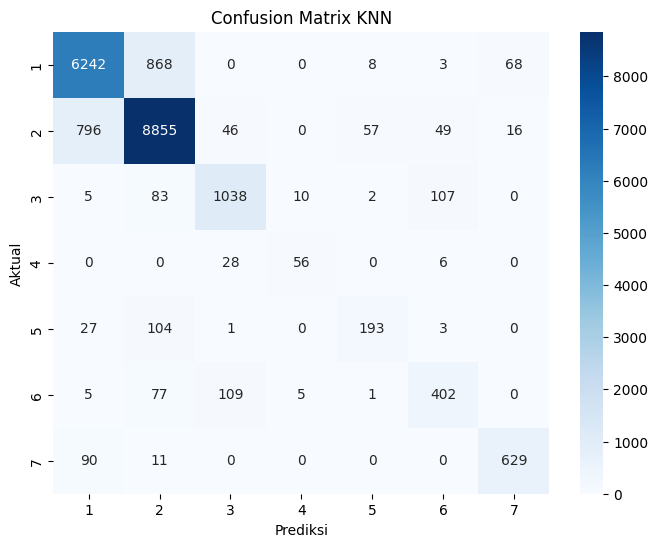

In [178]:
# Visualisasi Confusion Matrix
# menunjukkan jenis pohon mana yang sering tertukar.

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(label_testing, pred)
labels = sorted(label_testing.unique())

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix KNN')
plt.show()

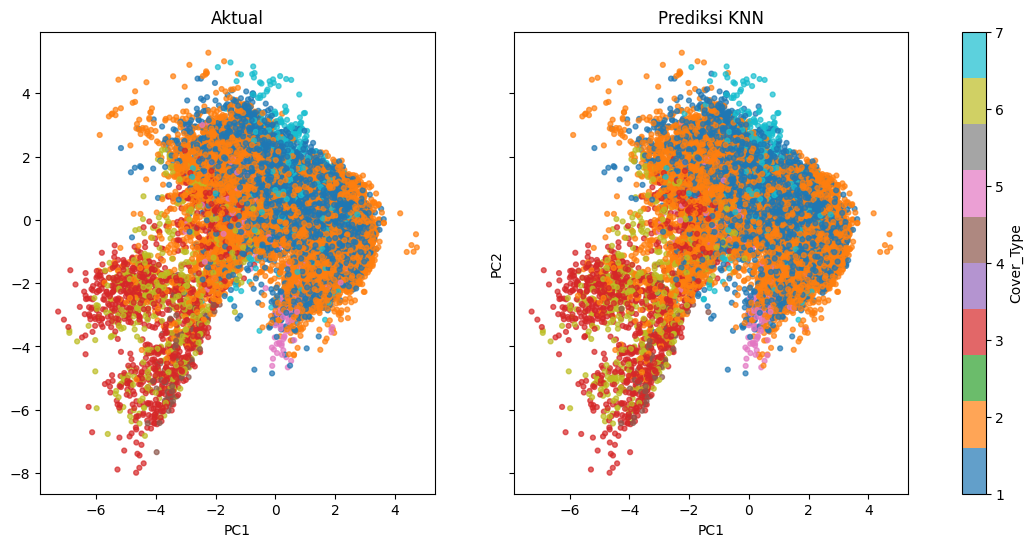

In [179]:
# Visualisasi Scatter PCA
# fiturnya terlalu banyak (54), jadi dikecilkan dulu jadi 2 dimensi dengan PCA. Dua plot ditaruh berdampingan: label aktual dan hasil prediksi.
# titik yang warnanya beda antara kiri dan kanan adalah yang salah prediksi.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
test_2d = pca.fit_transform(feature_testing_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, data, judul in zip(axes, [label_testing, pred], ['Aktual', 'Prediksi KNN']):
    sc = ax.scatter(test_2d[:, 0], test_2d[:, 1], c=data, cmap='tab10', s=12, alpha=0.7)
    ax.set_title(judul)
    ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.colorbar(sc, ax=axes, label='Cover_Type')
plt.show()

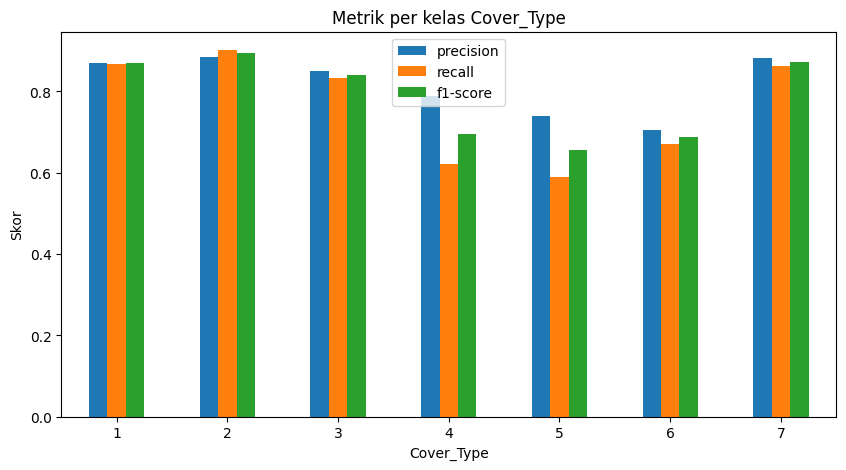

In [180]:
# Visualisasi Metrik per kelas
# Akurasi keseluruhan bisa menyembunyikan kelas yang buruk. Ini menampilkan precision, recall, dan f1 untuk tiap jenis pohon:

from sklearn.metrics import classification_report

report = classification_report(label_testing, pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.drop(['accuracy', 'macro avg', 'weighted avg'])

report_df[['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(10, 5))
plt.title('Metrik per kelas Cover_Type')
plt.xlabel('Cover_Type')
plt.ylabel('Skor')
plt.xticks(rotation=0)
plt.show()